In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1).zip


In [2]:
import pandas as pd
import numpy as np

# Get the uploaded filename automatically
filename = next(iter(uploaded))

# Load the dataset
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (50000, 7)


,tenure_months,monthly_usage_hours,has_multiple_devices,customer_support_calls,payment_failures,is_premium_plan,churn
0,39,30.953928,0,1,0,0,0
1,52,20.485203,0,0,0,0,0
2,29,21.684462,0,1,1,0,0
3,15,27.894281,0,1,0,1,0
4,43,19.250190,1,1,0,0,0


In [3]:
# Display column names
print("Column Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Summary statistics
print("\nSummary Statistics:")
display(df.describe(include="all").T)

Column Names:
['tenure_months', 'monthly_usage_hours', 'has_multiple_devices', 'customer_support_calls', 'payment_failures', 'is_premium_plan', 'churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   tenure_months           50000 non-null  int64  
 1   monthly_usage_hours     50000 non-null  float64
 2   has_multiple_devices    50000 non-null  int64  
 3   customer_support_calls  50000 non-null  int64  
 4   payment_failures        50000 non-null  int64  
 5   is_premium_plan         50000 non-null  int64  
 6   churn                   50000 non-null  int64  
dtypes: float64(1), int64(6)
memory usage: 2.7 MB

Missing Values:
tenure_months             0
monthly_usage_hours       0
has_multiple_devices      0
customer_support_calls    0
payment_failures          0
is_premium_plan           0
churn

,count,mean,std,min,25%,50%,75%,max
tenure_months,50000.0,30.029760,16.997771,1.0,15.00000,30.000000,45.000000,59.000000
monthly_usage_hours,50000.0,20.000411,4.996693,0.0,16.58975,20.026256,23.387508,38.726896
has_multiple_devices,50000.0,0.398820,0.489660,0.0,0.00000,0.000000,1.000000,1.000000
customer_support_calls,50000.0,1.205680,1.101236,0.0,0.00000,1.000000,2.000000,8.000000
payment_failures,50000.0,0.098780,0.298369,0.0,0.00000,0.000000,0.000000,1.000000
is_premium_plan,50000.0,0.298340,0.457534,0.0,0.00000,0.000000,1.000000,1.000000
churn,50000.0,0.020660,0.142245,0.0,0.00000,0.000000,0.000000,1.000000


Dataset shape: (50000, 7)

Target distribution:
churn
0    48967
1     1033
Name: count, dtype: int64

Target percentages:
churn
0    97.93
1     2.07
Name: proportion, dtype: float64

Training records: 40000
Testing records: 10000

Model: Logistic Regression
Training time: 0.219 seconds

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.80      0.89      9793
           1       0.08      0.88      0.15       207

    accuracy                           0.80     10000
   macro avg       0.54      0.84      0.52     10000
weighted avg       0.98      0.80      0.87     10000


Model: Decision Tree
Training time: 0.193 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      9793
           1       0.38      0.43      0.40       207

    accuracy                           0.97     10000
   macro avg       0.68      0.71      0.69     10000
weighted avg 

,Model,Training Time (seconds),Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,9.459,0.9789,0.4902,0.4831,0.4866,0.9303
1,Decision Tree,0.193,0.9738,0.3810,0.4251,0.4018,0.7053
0,Logistic Regression,0.219,0.8005,0.0846,0.8792,0.1543,0.9100


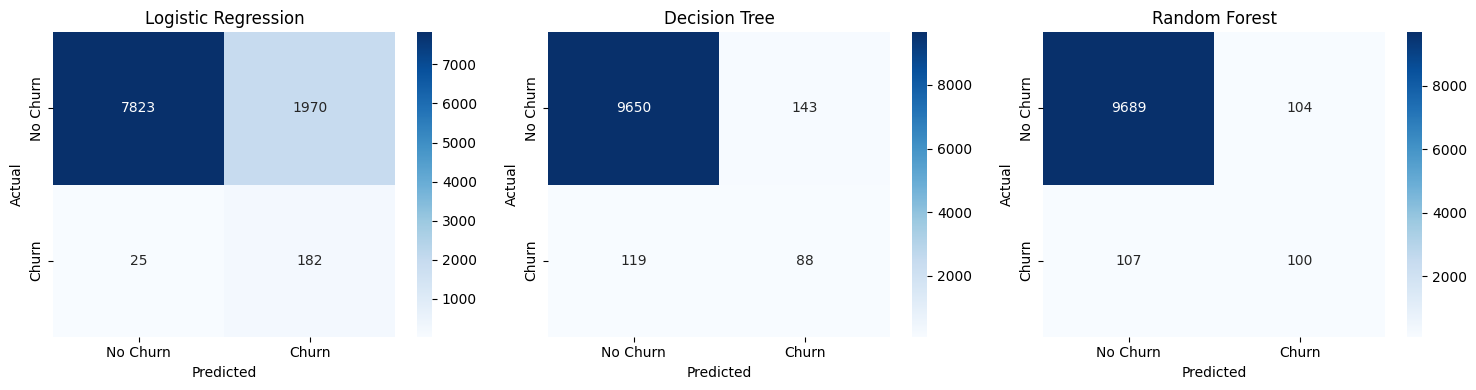

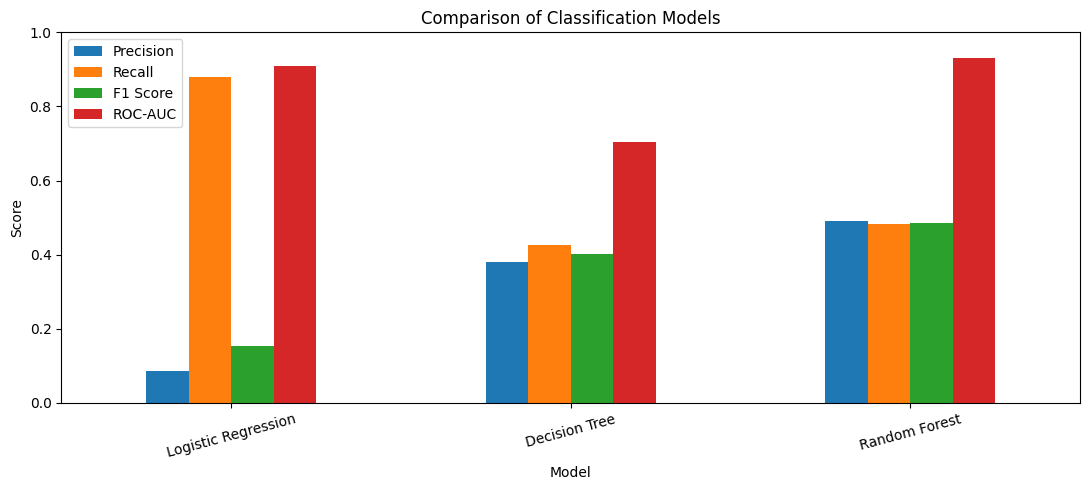

In [4]:

# ==========================================
# DEVIXO SOLUTIONS - TASK 02
# Build and Compare Machine Learning Models
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# 1. Separate features and target
X = df.drop(columns=["churn"])
y = df["churn"]

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

# 2. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# 3. Define three classification models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

# 4. Train and evaluate the models
results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time
    y_pred = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Training Time (seconds)": round(training_time, 3),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, model.predict_proba(X_test)[:, 1]
        )
    })

    print(f"\n{'=' * 50}")
    print("Model:", name)
    print("Training time:", round(training_time, 3), "seconds")
    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

# 5. Create the model comparison table
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON TABLE")
display(
    results_df.sort_values(
        by="F1 Score", ascending=False
    ).round(4)
)

# 6. Plot confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

# 7. Plot metric comparison
metrics = ["Precision", "Recall", "F1 Score", "ROC-AUC"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="best")
plt.tight_layout()
plt.show()


In [5]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
import pandas as pd
import time

# 1. Define the Random Forest model
rf = RandomForestClassifier(
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# 2. Define hyperparameter options
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", "log2"]
}

# 3. Search for better settings using training data only
search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=5,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

start = time.perf_counter()
search.fit(X_train, y_train)
tuning_time = time.perf_counter() - start

# 4. Get the best model
best_rf = search.best_estimator_

print("Best Parameters:")
print(search.best_params_)
print("\nBest cross-validation F1-score:",
      round(search.best_score_, 4))
print("Tuning time (seconds):", round(tuning_time, 2))

# 5. Evaluate on the untouched test set
y_tuned = best_rf.predict(X_test)

print("\nTuned Random Forest - Test Results")
print("Accuracy:", round(accuracy_score(y_test, y_tuned), 4))
print("Precision:", round(precision_score(
    y_test, y_tuned, zero_division=0), 4))
print("Recall:", round(recall_score(
    y_test, y_tuned, zero_division=0), 4))
print("F1-score:", round(f1_score(
    y_test, y_tuned, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_tuned, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_tuned))


Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Parameters:
{'n_estimators': 100, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 20}

Best cross-validation F1-score: 0.4719
Tuning time (seconds): 57.33

Tuned Random Forest - Test Results
Accuracy: 0.9753
Precision: 0.427
Recall: 0.5652
F1-score: 0.4865

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      9793
           1       0.43      0.57      0.49       207

    accuracy                           0.98     10000
   macro avg       0.71      0.77      0.74     10000
weighted avg       0.98      0.98      0.98     10000

Confusion Matrix:
[[9636  157]
 [  90  117]]


In [7]:

# Add the tuned Random Forest to the existing comparison table

tuned_row = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    "Training Time (seconds)": round(tuning_time, 3),
    "Accuracy": accuracy_score(y_test, y_tuned),
    "Precision": precision_score(y_test, y_tuned, zero_division=0),
    "Recall": recall_score(y_test, y_tuned, zero_division=0),
    "F1 Score": f1_score(y_test, y_tuned, zero_division=0),
    "ROC-AUC": roc_auc_score(
        y_test, best_rf.predict_proba(X_test)[:, 1]
    )
}])

final_comparison = pd.concat(
    [results_df, tuned_row], ignore_index=True
)

display(
    final_comparison.sort_values(
        "F1 Score", ascending=False
    ).round(4)
)

# Save the comparison table for your submission
final_comparison.to_csv(
    "Devixo_Task_02_Model_Comparison.csv", index=False
)

print("Comparison table saved successfully.")


,Model,Training Time (seconds),Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,9.459,0.9789,0.4902,0.4831,0.4866,0.9303
3,Tuned Random Forest,57.333,0.9753,0.4270,0.5652,0.4865,0.9593
1,Decision Tree,0.193,0.9738,0.3810,0.4251,0.4018,0.7053
0,Logistic Regression,0.219,0.8005,0.0846,0.8792,0.1543,0.9100


Comparison table saved successfully.


Random Forest Feature Importance:


,Importance
tenure_months,0.6102
monthly_usage_hours,0.2272
customer_support_calls,0.0764
payment_failures,0.0526
is_premium_plan,0.0279
has_multiple_devices,0.0057


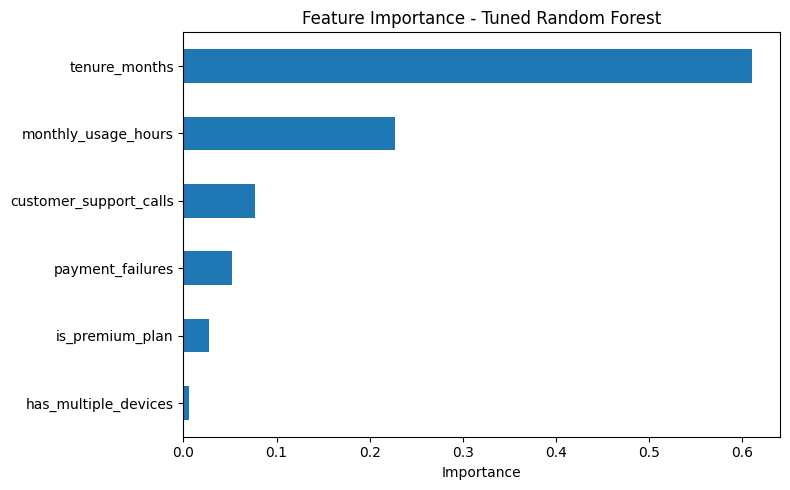

In [8]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    best_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Random Forest Feature Importance:")
display(importance.rename("Importance").to_frame().round(4))

importance.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Feature Importance - Tuned Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [9]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

corrected_results = []

for name, model in trained_models.items():
    pred = predictions[name]
    corrected_results.append({
        "Model": name,
        "Training Time (seconds)": results_df.loc[
            results_df["Model"] == name,
            "Training Time (seconds)"
        ].iloc[0],
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_test, model.predict_proba(X_test)[:, 1]
        )
    })

# Add tuned Random Forest
corrected_results.append({
    "Model": "Tuned Random Forest",
    "Training Time (seconds)": round(tuning_time, 3),
    "Accuracy": accuracy_score(y_test, y_tuned),
    "Precision": precision_score(y_test, y_tuned, zero_division=0),
    "Recall": recall_score(y_test, y_tuned, zero_division=0),
    "F1 Score": f1_score(y_test, y_tuned, zero_division=0),
    "ROC-AUC": roc_auc_score(
        y_test, best_rf.predict_proba(X_test)[:, 1]
    )
})

corrected_df = pd.DataFrame(corrected_results)
display(corrected_df.round(4))

corrected_df.to_csv(
    "Devixo_Task_02_Corrected_Comparison.csv", index=False
)
print("Corrected comparison saved.")


,Model,Training Time (seconds),Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.219,0.8005,0.0846,0.8792,0.1543,0.9100
1,Decision Tree,0.193,0.9738,0.3810,0.4251,0.4018,0.7053
2,Random Forest,9.459,0.9789,0.4902,0.4831,0.4866,0.9303
3,Tuned Random Forest,57.333,0.9753,0.4270,0.5652,0.4865,0.9593


Corrected comparison saved.
